# 26장 · LangGraph와 세 필드 State로 실행 흐름 읽기

도서 대출 기간을 물었더니 검색 함수가 문장 목록을 돌려줬습니다. 화면에 띄울 답은 한 문장입니다. 세 함수에 같은 상태를 건네고 각 함수가 어느 칸만 바꾸는지 따라갑니다. 이 장부터 수업용 Python 커널에 LangGraph와 langchain-core가 필요합니다. 검색과 문장 작성에는 로컬 규칙을 씁니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langgraph 1.2.16입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 질문을 다듬으면 어떤 값이 돌아올까요?

State는 한 질문을 처리하면서 여러 단계가 함께 읽는 값입니다. 여기서는 question에 질문, documents에 찾은 문장 목록, answer에 최종 안내를 담습니다. 노드가 값을 읽어 바꿀 부분만 돌려주면 그래프가 앞 상태에 합칩니다.

<!-- motion:state-patch -->
**한 필드만 돌려주면 나머지 필드는 지워질까요?**

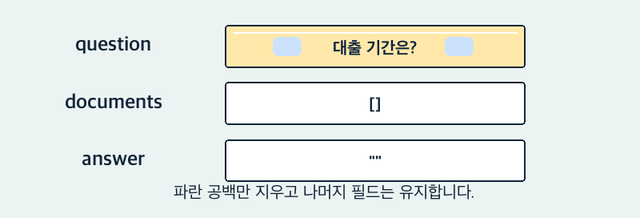

질문의 공백을 정리하는 노드는 question만 갱신합니다. documents의 빈 목록과 answer의 빈 문자열은 원래 칸에 남습니다.
<!-- /motion -->


### 셀 01 · 질문 앞뒤 공백 지우기

normalize가 돌려줄 딕셔너리의 키를 예측해 보세요.

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    documents: list[str]
    answer: str

def normalize(state: State) -> dict:
    question = state["question"].strip()
    if not question:
        raise ValueError("질문을 입력하세요.")
    return {"question": question}

initial = {'question': '  대출 기간은?  ', 'documents': [], 'answer': ''}
print(normalize(initial))

{'question': '대출 기간은?'}


question 하나만 보입니다. strip이 앞뒤 공백을 뺐고, normalize는 문서나 답변을 만들지 않았습니다. 이 반환값을 다음 단계의 전체 상태로 넘기면 나머지 키가 사라집니다.

### 셀 02 · 상태에 변경분 합치기

직접 호출에서는 딕셔너리를 합쳐 그래프가 하는 일을 한 번 따라 해 봅니다.

In [2]:
normalized = {**initial, **normalize(initial)}
print(normalized)

{'question': '대출 기간은?', 'documents': [], 'answer': ''}


documents와 answer의 빈 값이 남습니다. 두 칸은 이제 검색과 답변 노드가 채울 자리입니다.

## 검색 노드 뒤에서 답변 읽기

엣지는 어떤 함수를 다음에 부를지 정하는 연결입니다. START에서 normalize, lookup, compose 순으로 연결한 뒤 END에서 멈춥니다. 검색 결과를 미리 써 넣지 않고 질문에 들어 있는 낱말을 자료와 대조합니다.

### 초기 상태와 세 노드의 변경값

**초기 상태 만들기**　질문을 넣고 결과 칸은 비웁니다.

```
question  = '  대출 기간은?  '
documents = []
answer    = ""
```

**질문의 공백 제거**　question만 갱신하고 다른 키는 유지합니다.

```
question  = '대출 기간은?'
documents = []
answer    = ""
```

**질문에 맞는 문장 조회**　가상 문서 중 대출 키워드가 맞는 문장을 고릅니다.

```
question  = '대출 기간은?'
documents = ["도서 대출 기간은 14일입니다."]
answer    = ""
```

**문서를 답변으로 연결**　documents를 읽고 answer를 갱신합니다.

```
question  = '대출 기간은?'
documents = ["도서 대출 기간은 14일입니다."]
answer    = "도서 대출 기간은 14일입니다."
```


### 셀 03 · 세 노드 연결하기

이번 셀의 lookup은 노트북 안에 넣어 둔 두 가상 문장에서 찾습니다. 등록된 노드 이름과 엣지의 이름을 맞춰 보세요.

초기값부터 normalize, lookup, compose 순서로 따라가세요. 한 노드가 돌려주는 사전은 이번에 바꿀 칸만 담습니다. 나머지 두 칸은 앞 상태의 값을 유지합니다.

In [3]:
rows = [{'id': 'library-1', 'keyword': '대출', 'text': '도서 대출 기간은 14일입니다.'},
 {'id': 'library-2', 'keyword': '휴관', 'text': '도서관은 월요일에 휴관합니다.'}]

def lookup(state):
    found = [r['text'] for r in rows if r['keyword'] in state['question']]
    return {'documents': found}

def compose(state: State) -> dict:
    documents = state["documents"]
    answer = " / ".join(documents) if documents else "제공된 문서에서 확인할 수 없습니다."
    return {"answer": answer}

def make_graph():
    builder = StateGraph(State)
    builder.add_node("normalize", normalize)
    builder.add_node("lookup", lookup)
    builder.add_node("compose", compose)
    builder.add_edge(START, "normalize")
    builder.add_edge("normalize", "lookup")
    builder.add_edge("lookup", "compose")
    builder.add_edge("compose", END)
    return builder.compile()

graph = make_graph()
print(graph.invoke(initial)['answer'])

도서 대출 기간은 14일입니다.


14일이라는 문장이 나옵니다. lookup이 대출 문장을 골라 documents에 넣었고 compose는 그대로 이어 붙였습니다. 모델에 날짜를 묻는 과정은 없습니다.

### 과제 04 · 휴관 질문의 근거 확인하기

질문을 ‘휴관 요일은?’로 바꾸어 실행하고 최종 상태에서 documents만 표시하세요.

In [4]:
# 초기 상태의 질문을 바꾼 뒤 그래프에 넘기세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>request = {**initial, &#x27;question&#x27;: &#x27;휴관 요일은?&#x27;}
print(graph.invoke(request)[&#x27;documents&#x27;])</code></pre>
<p>실행 결과</p><pre><code>[&#x27;도서관은 월요일에 휴관합니다.&#x27;]</code></pre>
<p>휴관에 해당하는 문장 한 개가 목록에 남습니다. answer가 문자열인 데 비해 이 칸은 검색이 여러 건일 수 있어 목록입니다.</p>
</details>

## 돌아보기

주차 질문을 넣었을 때 답변을 만든 노드와 빈 목록을 만든 노드를 구별해 보세요. 다음 장은 빈 검색 뒤 한 번 더 찾을지 결정합니다.